# Reproducible methods and provenance

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/21-reproducibility.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/21-reproducibility.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `e0637741a4b521415232c98de425c22aff4bf0da0710d93f4f1c9e4cd19ef41c`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Reproducible methods and provenance

**Lesson 21 · Original synthetic data · Independent educational project**

## Objectives

Test random seeds; record transformations and hash an artifact.

[Previous](20-performance.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/21-reproducibility.ipynb) · [Next](22-capstone.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=21-reproducibility.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

Artifact SHA-256: 0e550f3f7a53084afb198048f9b6092b1e5213a14fd381935e03db31ca67e1bf
{'source': 'Original synthetic teaching data; not observations or DestinE model output', 'seed': 42, 'method': 'cosine-weighted mean; rounded to 6 decimals', 'units': 'K', 'numpy_version': '2.3.3'}


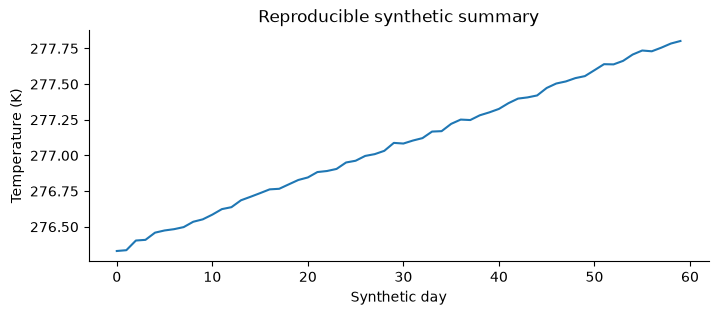

In [2]:
import hashlib, json
a = lab.synthetic_cube(seed=42); b = lab.synthetic_cube(seed=42); c = lab.synthetic_cube(seed=43)
assert np.array_equal(a["temperature"], b["temperature"])
assert not np.array_equal(a["temperature"], c["temperature"])
summary = np.round(lab.global_mean(a["temperature"], a["lat"]), 6)
record = {"source": lab.PROVENANCE, "seed": 42, "method": "cosine-weighted mean; rounded to 6 decimals",
          "units": "K", "numpy_version": np.__version__, "values": summary.tolist()}
serialized = json.dumps(record, sort_keys=True).encode()
digest = hashlib.sha256(serialized).hexdigest()
print("Artifact SHA-256:", digest)
print({key: value for key, value in record.items() if key != "values"})
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(summary); ax.set(xlabel="Synthetic day", ylabel="Temperature (K)", title="Reproducible synthetic summary")
plt.show()
assert len(digest) == 64

## Exercise

Change the seed or rounding precision and recompute the hash. Separate numerical reproducibility from byte-for-byte reproducibility.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

A hash detects changed bytes, not truth or licensing. Version and method records explain changes that a hash alone cannot; portable results should use documented tolerances.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://numpy.org/doc/stable/reference/random/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).